In [1]:
import pandas as pd
from pathlib import Path

In [8]:
GEN_PATH = "../../01_data/2_cleaned/generation/hourly_solar_wind_generation_2020_2025.parquet"
PRICE_PATH = "../../01_data/2_cleaned/rtm_price/rtm_price_aggregated_2021_2025.csv"
LOAD_PATH = "../../01_data/2_cleaned/load/total_load_20201231_20260526.csv"

OUT_DIR = Path("../../01_data/3_analysis/additional")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
df_gen = pd.read_parquet(GEN_PATH)
df_gen['datetime'] = pd.to_datetime(df_gen['datetime'])
df_gen.head()

,datetime,renewable_gen
0,2020-01-01 01:00:00,12832.85
1,2020-01-01 02:00:00,13328.73
2,2020-01-01 03:00:00,13920.06
3,2020-01-01 04:00:00,14443.91
4,2020-01-01 05:00:00,14713.70


In [4]:
df_price = pd.read_csv(PRICE_PATH)
df_price['date_time'] = pd.to_datetime(df_price['date_time'])
df_price.head()

,date_time,avg_rtm_price
0,2021-01-01 01:00:00,18.173500
1,2021-01-01 02:00:00,20.960833
2,2021-01-01 03:00:00,20.779667
3,2021-01-01 04:00:00,16.416667
4,2021-01-01 05:00:00,18.075333


In [5]:
df_load = pd.read_csv(LOAD_PATH)
df_load['datetime'] = pd.to_datetime(df_load['datetime'])
df_load.head()

,datetime,total_load
0,2020-12-31 01:00:00,39174.39
1,2020-12-31 02:00:00,38284.84
2,2020-12-31 03:00:00,37776.69
3,2020-12-31 04:00:00,37781.84
4,2020-12-31 05:00:00,38455.69


In [6]:
df_agg = pd.merge(df_price, df_gen, left_on='date_time', right_on='datetime')
df_agg = pd.merge(df_agg, df_load, left_on='datetime', right_on='datetime')
df_agg = df_agg.filter(['datetime', 'avg_rtm_price', 'renewable_gen', 'total_load'])
df_agg

,datetime,avg_rtm_price,renewable_gen,total_load
0,2021-01-01 01:00:00,18.173500,13984.76,43713.80
1,2021-01-01 02:00:00,20.960833,14289.14,43314.37
2,2021-01-01 03:00:00,20.779667,14221.11,43048.35
3,2021-01-01 04:00:00,16.416667,13246.11,43073.65
4,2021-01-01 05:00:00,18.075333,12235.54,43448.89
...,...,...,...,...
43793,2025-12-31 20:00:00,55.840833,9979.51,49805.51
43794,2025-12-31 21:00:00,31.055000,13074.09,49013.71
43795,2025-12-31 22:00:00,24.260333,15597.96,48254.52
43796,2025-12-31 23:00:00,20.272500,17978.92,47395.40


In [10]:
# export to csv
df_agg.to_csv(OUT_DIR/'agg_price_load_REgen_2021_2025.csv', index=False)

Text(0.5, 0, 'RTM Price')

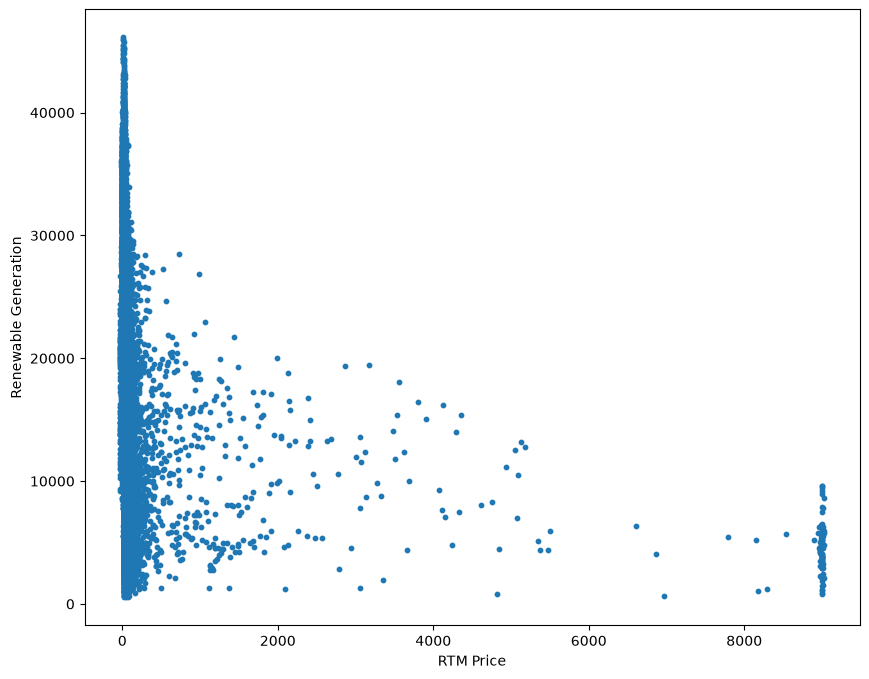

In [27]:
# plots

import matplotlib.pyplot as plt

plt.subplots(figsize=(10, 8))
plt.scatter(df_agg['avg_rtm_price'], df_agg['renewable_gen'], s=10)

plt.ylabel("Renewable Generation")
plt.xlabel("RTM Price")

Text(0.5, 0, 'Datetime')

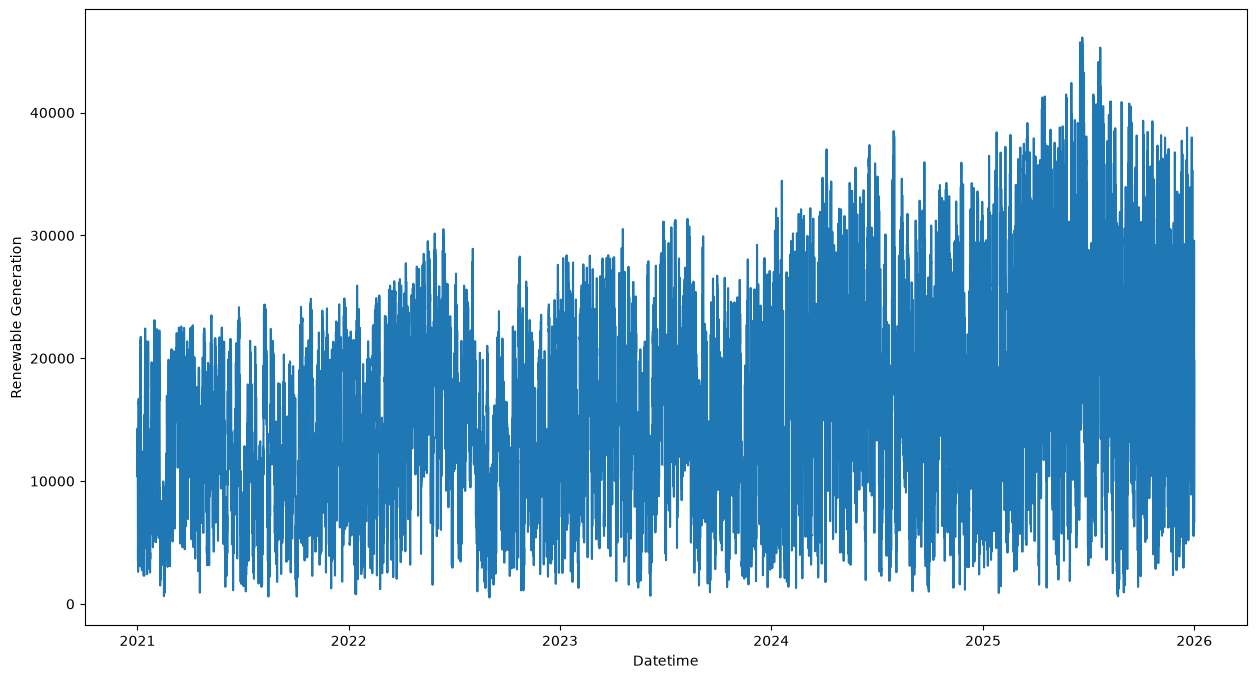

In [30]:
plt.subplots(figsize=(15, 8))
plt.plot(df_agg['datetime'], df_agg['renewable_gen'])

plt.ylabel("Renewable Generation")
plt.xlabel("Datetime")

Text(0.5, 0, 'Datetime')

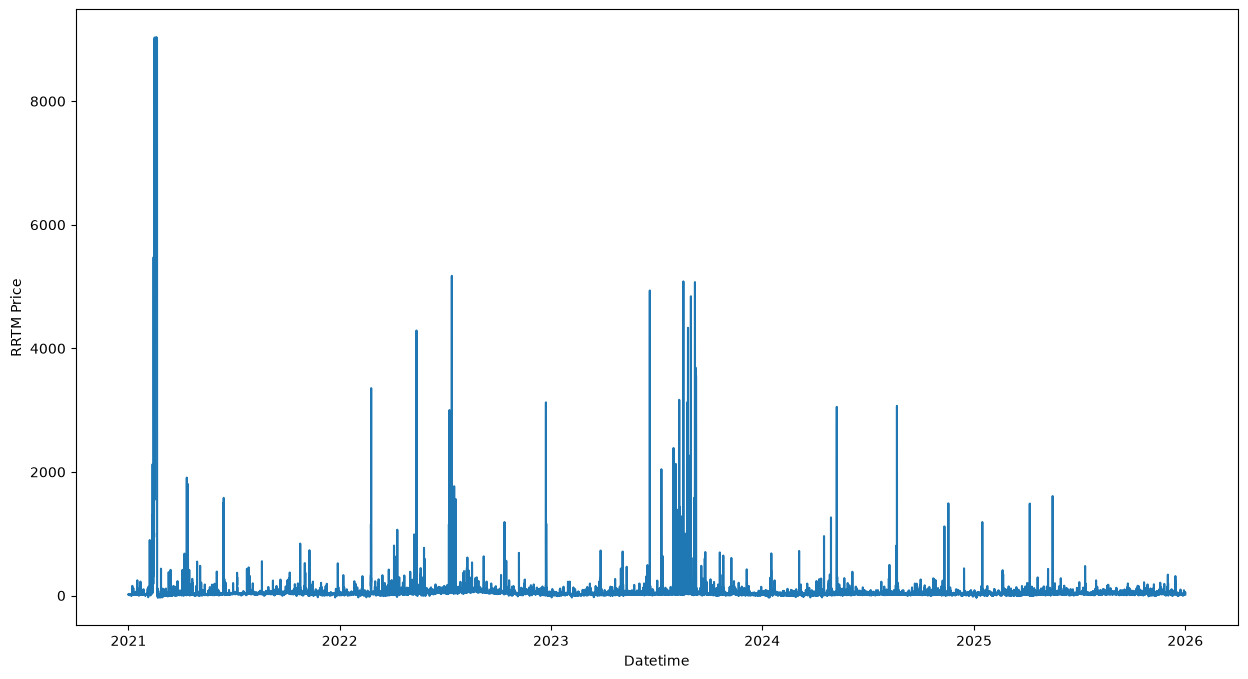

In [31]:
plt.subplots(figsize=(15, 8))
plt.plot(df_agg['datetime'], df_agg['avg_rtm_price'])

plt.ylabel("RRTM Price")
plt.xlabel("Datetime")